BTC-CAPM-FAMA

In [33]:
import pandas as pd

def read_csv_sorted(path, date_col, rename_to=None):
    """读取 CSV 并按日期排序，支持重命名日期列"""
    df = pd.read_csv(path, parse_dates=[date_col]).sort_values(date_col)
    return df.rename(columns={date_col: rename_to}) if rename_to else df

# 文件路径
btc_path = r"D:\桌面\绿色货币\数据总库\btc历史数据\Bitcoin_full_data.csv"
us_treasury_path = r"D:\桌面\绿色货币\数据总库\宏观经济数据\美国国债\us_treasury_daliy_data.csv"
# ghg_path = r"D:\桌面\绿色货币\数据总库\数字货币能源消耗数据\Historical Bitcoin greenhouse gas emissions.csv"
# electricity_path = r"D:\桌面\绿色货币\数据总库\数字货币能源消耗数据\Historical btc annualised electricity consumption.csv"
electricity_path = r"D:\桌面\绿色货币\数据总库\数字货币能源消耗数据\bitcoin-energy-consumpti.csv"
gold_path = r"D:\桌面\绿色货币\数据总库\宏观经济数据\gold_USD Historical Data.csv"
sp500_path = r"D:\桌面\绿色货币\数据总库\宏观经济数据\S&P 500 Historical Data.csv"
Oil_path = r"D:\桌面\绿色货币\数据总库\宏观经济数据\Crude Oil WTI Futures Historical Data.csv"



# 读取数据并处理日期列
btc_df = read_csv_sorted(btc_path, "timestamp", "Date")
us_treasury_df = read_csv_sorted(us_treasury_path, "Date")
# ghg_df = read_csv_sorted(ghg_path, "Date and Time", "Date")
# electricity_df = read_csv_sorted(electricity_path, "Date and Time", "Date")
electricity_df = read_csv_sorted(electricity_path, "DateTime", "Date")
gold_df = read_csv_sorted(gold_path, "Date")
sp500_df = read_csv_sorted(sp500_path, "Date")
Oil_df = read_csv_sorted(Oil_path, "Date")

# 以 btc_df 为基础，依次合并其它数据
merged_df = btc_df.copy()
for df in [us_treasury_df, gold_df, sp500_df, Oil_df, electricity_df]:
    merged_df = pd.merge_asof(merged_df, df, on="Date", direction="backward")

# 设置索引、删除缺失行，并转换非 "name" 列中的数值（移除逗号）
merged_df = merged_df.set_index("Date").dropna()
for col in merged_df.columns:
    if col != "name":
        merged_df[col] = pd.to_numeric(merged_df[col].astype(str).str.replace(',', ''), errors='coerce')

merged_df.to_csv('btc_mergeddata.csv')


In [34]:
# 以 merged_df 拷贝构造新的 DataFrame
datafeature = merged_df.copy()

# 计算日收益率（百分比变化），注意可能需要根据实际需求选择 pct_change 或对数收益率
datafeature["return"] = datafeature["close"].pct_change()

# 计算30天滚动波动率（标准差）
datafeature["volatility"] = datafeature["return"].rolling(window=30).std()
datafeature["MA30"] = datafeature["close"].rolling(window=30).mean()
datafeature["MA5"] = datafeature["close"].rolling(window=5).mean()
# 构造因子： (30天平均成交量 - 10天平均成交量) / 30天平均成交量
datafeature["market_sentiment"] = (
    datafeature["volume"].rolling(window=30).mean() - datafeature["volume"].rolling(window=5).mean()
) / datafeature["volume"].rolling(window=30).mean()

datafeature["return_riskfree"] = datafeature["return"] - datafeature["1 Yr"]/100

# 查看结果
datafeature = datafeature.dropna()

datafeature.to_csv('btc_mergeddata_feature.csv')
datafeature.columns
print(datafeature)

           name          open          high           low         close  \
Date                                                                      
2017-03-12  BTC   1176.619995   1226.979980   1175.359985   1221.380005   
2017-03-13  BTC   1221.780029   1237.369995   1217.030029   1231.920044   
2017-03-14  BTC   1232.160034   1244.810059   1220.719971   1240.000000   
2017-03-15  BTC   1240.160034   1251.609985   1239.750000   1249.609985   
2017-03-16  BTC   1251.329956   1257.979980   1152.439941   1187.810059   
...         ...           ...           ...           ...           ...   
2024-12-27  BTC  95704.974586  97294.846420  93310.743804  94164.860348   
2024-12-28  BTC  94160.186223  95525.898522  94014.286497  95163.931926   
2024-12-29  BTC  95174.055117  95174.878402  92881.791870  93530.228438   
2024-12-30  BTC  93527.197497  94903.323896  91317.135460  92643.214604   
2024-12-31  BTC  92643.251222  96090.603788  91914.027783  93429.202811   

                  volume

Random Forest - Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}
Random Forest - Train R²: 0.6710, Test R²: -0.1704, MSE: 0.0009
Random Forest - Feature importance ranking:
marketCap                         0.112150
annualised_consumption_MIN_TWh    0.081620
market_sentiment                  0.078808
volatility                        0.078097
MA5                               0.074842
Hydro_only_MtCO2e                 0.071865
MA30                              0.068753
Coal_only_MtCO2e                  0.065922
SP500Price                        0.065520
power_MAX_GW                      0.063132
GoldPrice                         0.058942
OilPrice                          0.057272
Ten_Yr                            0.047676
Five_Yr                           0.043158
One_Yr                            0.032243
dtype: float64


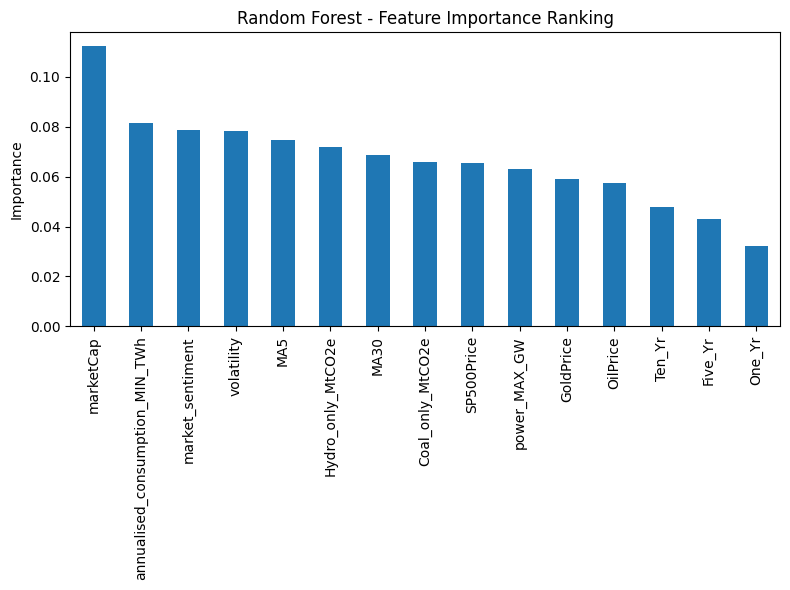

XGBoost - Best parameters: {'subsample': 0.7, 'n_estimators': 10, 'max_depth': 7, 'learning_rate': 0.2}
XGBoost - Train R²: 0.3403, Test R²: -0.0767, MSE: 0.0008
XGBoost - Feature importance ranking:
Coal_only_MtCO2e                  0.101705
SP500Price                        0.096424
annualised_consumption_MIN_TWh    0.087195
power_MAX_GW                      0.080939
MA5                               0.078006
MA30                              0.077990
Hydro_only_MtCO2e                 0.066186
marketCap                         0.065037
GoldPrice                         0.059668
Five_Yr                           0.059365
OilPrice                          0.051145
Ten_Yr                            0.047184
market_sentiment                  0.046387
volatility                        0.043829
One_Yr                            0.038940
dtype: float32


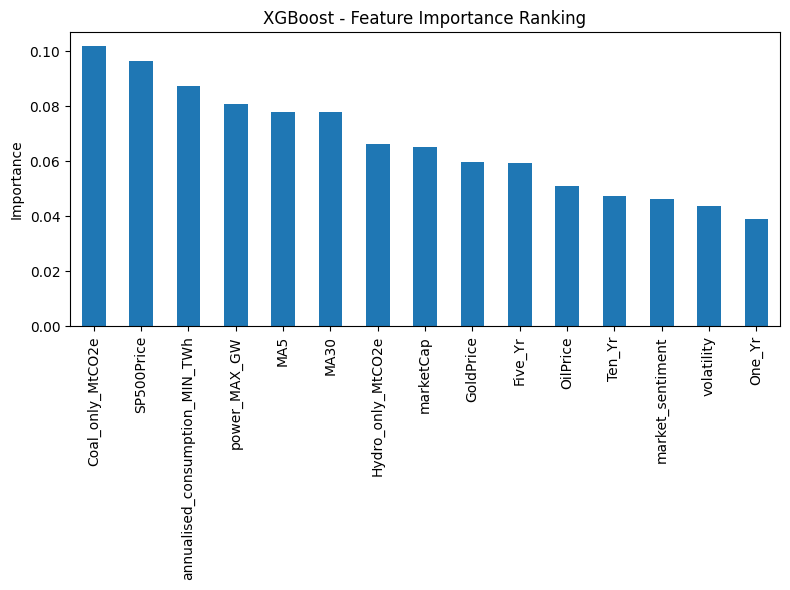

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000656 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3768
[LightGBM] [Info] Number of data points in the train set: 4030, number of used features: 15
[LightGBM] [Info] Start training from score 0.004107
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

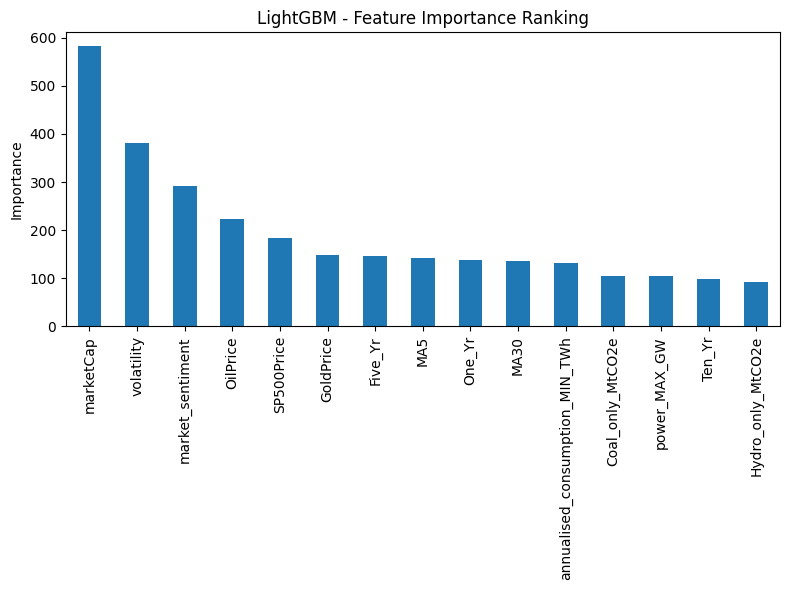

ExtraTrees - Best parameters: {'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
ExtraTrees - Train R²: 0.4168, Test R²: -0.0491, MSE: 0.0008
ExtraTrees - Feature importance ranking:
marketCap                         0.103757
volatility                        0.082398
market_sentiment                  0.072175
GoldPrice                         0.068343
One_Yr                            0.064885
Ten_Yr                            0.064663
MA30                              0.063805
annualised_consumption_MIN_TWh    0.062608
Five_Yr                           0.062493
MA5                               0.062188
OilPrice                          0.061144
Coal_only_MtCO2e                  0.059157
SP500Price                        0.058936
Hydro_only_MtCO2e                 0.057524
power_MAX_GW                      0.055925
dtype: float64


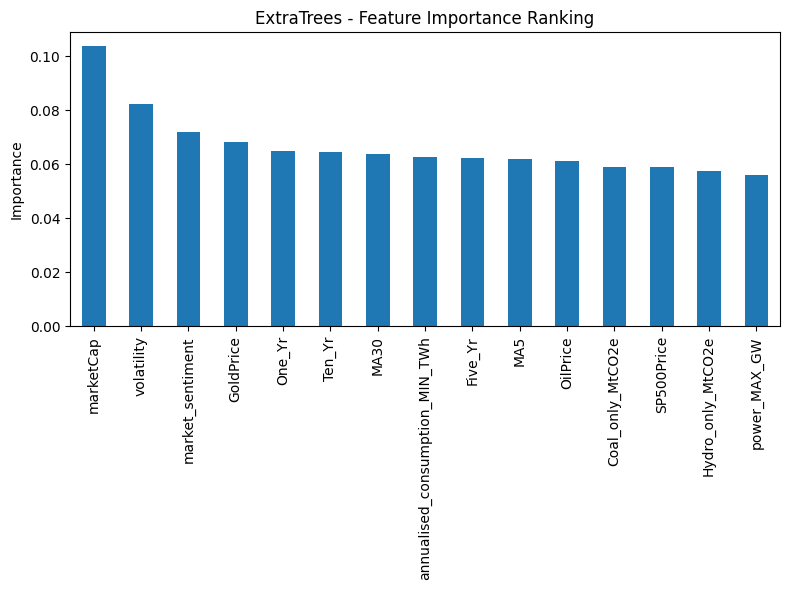

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import ElasticNet, Lasso
import xgboost as xgb
import lightgbm as lgb

import warnings
warnings.filterwarnings("ignore")

# 假设 datafeature 已经准备好，并且其索引为日期
# 1. 构造特征列表（确保名称唯一）
# 1. 重新命名特征，确保没有特殊字符
features = ["volatility", "market_sentiment", "Hydro_only_MtCO2e", "Coal_only_MtCO2e",
            "SP500Price", "OilPrice", "One_Yr", "Five_Yr", "Ten_Yr", "marketCap", 
            "MA30", "MA5", "GoldPrice", "power_MAX_GW", "annualised_consumption_MIN_TWh"]

# 2. 重新命名 DataFrame 中的列
data_sorted = datafeature.rename(columns={
    "Hydro-only, MtCO2e": "Hydro_only_MtCO2e",
    "Coal-only, MtCO2e": "Coal_only_MtCO2e",
    "1 Yr": "One_Yr",
    "5 Yr": "Five_Yr",
    "10 Yr": "Ten_Yr",
    "power MAX, GW": "power_MAX_GW",
    "annualised consumption MIN, TWh": "annualised_consumption_MIN_TWh"
})
X = data_sorted[features]
y = data_sorted["return"]

# 划分训练集和测试集（前80%为训练集）
split_index = int(len(data_sorted) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# 使用时间序列交叉验证
tscv = TimeSeriesSplit(n_splits=3)

def tune_and_evaluate(model, param_dist, X_train, y_train, X_test, y_test, model_name):
    """
    使用 RandomizedSearchCV 调参、评估并绘制特征重要性（若模型支持）
    对于线性模型，使用 coef_ 作为特征重要性；对于树模型则使用 feature_importances_
    """
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=5,
        cv=tscv,
        scoring="neg_mean_squared_error",
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    print(f"{model_name} - Best parameters:", search.best_params_)
    
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2_train = best_model.score(X_train, y_train)
    r2_test = best_model.score(X_test, y_test)
    print(f"{model_name} - Train R²: {r2_train:.4f}, Test R²: {r2_test:.4f}, MSE: {mse:.4f}")
    
    # 绘制特征重要性：对于树模型使用 feature_importances_，线性模型则使用 coef_
    if hasattr(best_model, "feature_importances_"):
        importances = best_model.feature_importances_
        fi = pd.Series(importances, index=features).sort_values(ascending=False)
        print(f"{model_name} - Feature importance ranking:")
        print(fi)
        plt.figure(figsize=(8, 6))
        fi.plot(kind="bar")
        plt.title(f"{model_name} - Feature Importance Ranking")
        plt.ylabel("Importance")
        plt.tight_layout()
        plt.show()
    elif hasattr(best_model, "coef_"):
        coefs = best_model.coef_
        # 如果系数为多维则压平
        if coefs.ndim > 1:
            coefs = coefs.ravel()
        fi = pd.Series(coefs, index=features).sort_values(ascending=False)
        print(f"{model_name} - Feature coefficients ranking:")
        print(fi)
        plt.figure(figsize=(8, 6))
        fi.plot(kind="bar")
        plt.title(f"{model_name} - Feature Coefficients Ranking")
        plt.ylabel("Coefficient")
        plt.tight_layout()
        plt.show()
    else:
        print(f"{model_name} does not provide feature importance information.")
    
    return best_model

###############################################
# 随机森林模型 (Random Forest)
###############################################
param_dist_rf = {
    "n_estimators": [10, 50, 100, 200, 500],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["auto", "sqrt", "log2"]
}
rf = RandomForestRegressor(random_state=42)
best_rf = tune_and_evaluate(rf, param_dist_rf, X_train, y_train, X_test, y_test, "Random Forest")

###############################################
# XGBoost 模型
###############################################
param_dist_xgb = {
    "n_estimators": [10, 30, 50, 100],
    "max_depth": [3, 5, 7, None],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.7, 0.8]
}
xgb_reg = xgb.XGBRegressor(random_state=42, objective="reg:squarederror")
best_xgb = tune_and_evaluate(xgb_reg, param_dist_xgb, X_train, y_train, X_test, y_test, "XGBoost")

###############################################
# LightGBM 模型
###############################################
param_dist_lgb = {
    "n_estimators": [50, 100, 200, 500],
    "max_depth": [3, 5, 7, None],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0]
}
lgb_reg = lgb.LGBMRegressor(random_state=42)
best_lgb = tune_and_evaluate(lgb_reg, param_dist_lgb, X_train, y_train, X_test, y_test, "LightGBM")

###############################################
# ExtraTrees 模型
###############################################
param_dist_et = {
    "n_estimators": [10, 50, 100, 200, 500],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["auto", "sqrt", "log2"]
}
et = ExtraTreesRegressor(random_state=42)
best_et = tune_and_evaluate(et, param_dist_et, X_train, y_train, X_test, y_test, "ExtraTrees")

